In [1]:
import torch
from torch import nn
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import random_split, DataLoader, Subset
import matplotlib.pyplot as plt

In [2]:
train_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    ),
])

eval_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    ),
])

In [3]:
train_aug_data = datasets.CIFAR10(
    root="data", train=True, download=True, transform=train_transform
)
train_eval_data = datasets.CIFAR10(
    root="data", train=True, download=True, transform=eval_transform
)
testing_data = datasets.CIFAR10(
    root="data", train=False, download=True, transform=eval_transform
)
indices = torch.randperm(
    len(train_aug_data), generator=torch.Generator().manual_seed(2)
).tolist()

train_set = Subset(train_aug_data, indices[:45_000])
val_set = Subset(train_eval_data, indices[45_000:])

In [4]:
train_dl = DataLoader(train_set, batch_size=64, shuffle=True)
val_dl = DataLoader(val_set, batch_size=64, shuffle=False)
test_dl = DataLoader(testing_data, batch_size=64, shuffle=False)

In [5]:
device = torch.accelerator.current_accelerator().type
print(device)

mps


In [6]:
images,labels = next(iter(test_dl))
print(images.shape)
print(labels.shape)

torch.Size([64, 3, 32, 32])
torch.Size([64])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1770618..2.6952007].


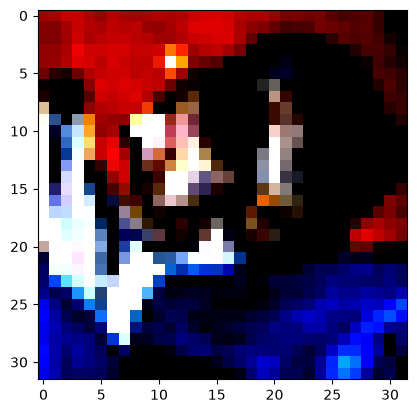

In [7]:
img = images[0]
plt.imshow(img.permute(1,2,0))
plt.show()

In [8]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64,64,3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64*8*8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128,10)
        )

    def forward(self, x):
        
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)



NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0

In [9]:
loss_fn = nn.CrossEntropyLoss()
optimiser = torch.optim.Adam(model.parameters(), lr = 1e-3)


In [10]:
def train(dataloader, model, loss_fn, optimiser):
    size = len(dataloader.dataset)
    model.train()
    for batch,(X,y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        loss.backward()
        optimiser.step()
        optimiser.zero_grad()
        if (batch%100==0):
            loss, current = loss.item(), (batch+1)*len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


In [11]:
def test(dataloader, model, loss_fn):
    model.eval()
    test_loss, correct = 0,0
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    with (torch.no_grad()):
        for X,y in dataloader:
            X,y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred,y).item()
            correct += (pred.argmax(dim=1)==y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Accuracy: {100*correct}, Avg loss: {test_loss}")


In [12]:
epochs = 30
for t in range(epochs):
    print(f"epoch {t+1}")
    train(train_dl, model=model, loss_fn=loss_fn, optimiser=optimiser)
    test(val_dl, model = model, loss_fn=loss_fn)

epoch 1
loss: 2.346099  [   64/45000]
loss: 1.753036  [ 6464/45000]
loss: 1.446676  [12864/45000]
loss: 1.510720  [19264/45000]
loss: 1.366410  [25664/45000]
loss: 1.544823  [32064/45000]
loss: 1.505701  [38464/45000]
loss: 1.489866  [44864/45000]
Accuracy: 49.519999999999996, Avg loss: 1.410419999798642
epoch 2
loss: 1.440334  [   64/45000]
loss: 1.513646  [ 6464/45000]
loss: 1.526833  [12864/45000]
loss: 1.400249  [19264/45000]
loss: 1.067603  [25664/45000]
loss: 1.282544  [32064/45000]
loss: 1.330520  [38464/45000]
loss: 1.091778  [44864/45000]
Accuracy: 62.62, Avg loss: 1.0220658326450782
epoch 3
loss: 0.929468  [   64/45000]
loss: 1.467686  [ 6464/45000]
loss: 0.986696  [12864/45000]
loss: 1.274093  [19264/45000]
loss: 1.303034  [25664/45000]
loss: 1.064051  [32064/45000]
loss: 1.184001  [38464/45000]
loss: 0.835476  [44864/45000]
Accuracy: 64.08, Avg loss: 1.0072664316696456
epoch 4
loss: 0.972444  [   64/45000]
loss: 0.867002  [ 6464/45000]
loss: 1.442080  [12864/45000]
loss: 0.

In [13]:
test(test_dl, model=model, loss_fn=loss_fn)

Accuracy: 82.72, Avg loss: 0.5027851541141036


In [14]:
torch.save(model.state_dict(), "cifar10_cnn.pth")